# Сравнение FP32 и AMP FP16

Запустите все ячейки сверху вниз. Два независимых обучения выполняются
последовательно. Начальные веса, данные, размер батча и число эпох одинаковые.
Валидация в обоих режимах проходит в FP32. Для пробного запуска можно снизить
`EPOCHS` в ячейке настроек. Для воспроизведения итогового сравнения используйте 130.

In [1]:
from pathlib import Path
import sys

import torch

ROOT = Path.cwd()
if not (ROOT / "utils" / "alexnet.py").is_file():
    ROOT = ROOT.parent
if not (ROOT / "utils" / "alexnet.py").is_file():
    raise RuntimeError("Откройте ноутбук из корня проекта или из папки notebooks.")
sys.path.insert(0, str(ROOT))

from utils.data_utils import load_training_data

DATA_DIR = ROOT / "data"
ARTIFACTS = ROOT / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)
SEED = 52
BATCH_SIZE = 512

if not torch.cuda.is_available():
    raise RuntimeError("Для этих экспериментов нужна CUDA. Проверьте выбранное ядро.")
DEVICE = torch.device("cuda")
print(torch.cuda.get_device_name(DEVICE), "PyTorch", torch.__version__)

from utils.train_utils import fit

EPOCHS = 130
WORKERS = 2
data = load_training_data(DATA_DIR, SEED)

NVIDIA GeForce RTX 2080 Ti PyTorch 2.14.1+cu130


In [2]:
fp32_history = fit(
    data, DEVICE, ARTIFACTS / "fp32",
    epochs=EPOCHS, seed=SEED, batch_size=BATCH_SIZE, workers=WORKERS,
)

FP32 | эпоха   1/130 | train 16.66% | val 32.58% | val loss 1.8376 | 19.3 с
FP32 | эпоха   2/130 | train 28.38% | val 41.10% | val loss 1.5757 | 53.7 с
FP32 | эпоха   3/130 | train 35.64% | val 47.67% | val loss 1.4327 | 10.3 с
FP32 | эпоха   4/130 | train 40.97% | val 52.72% | val loss 1.3016 | 10.3 с
FP32 | эпоха   5/130 | train 46.49% | val 55.45% | val loss 1.2299 | 10.3 с
FP32 | эпоха   6/130 | train 49.80% | val 56.55% | val loss 1.1796 | 10.4 с
FP32 | эпоха   7/130 | train 53.02% | val 62.62% | val loss 1.0416 | 10.4 с
FP32 | эпоха   8/130 | train 55.69% | val 65.16% | val loss 0.9812 | 10.5 с
FP32 | эпоха   9/130 | train 58.07% | val 64.08% | val loss 1.0234 | 10.4 с
FP32 | эпоха  10/130 | train 60.82% | val 69.50% | val loss 0.8407 | 10.4 с
FP32 | эпоха  11/130 | train 63.00% | val 70.90% | val loss 0.8166 | 10.4 с
FP32 | эпоха  12/130 | train 64.72% | val 71.61% | val loss 0.8106 | 10.4 с
FP32 | эпоха  13/130 | train 66.03% | val 73.28% | val loss 0.7540 | 10.4 с
FP32 | эпоха

In [3]:
amp_history = fit(
    data, DEVICE, ARTIFACTS / "amp_fp16",
    epochs=EPOCHS, seed=SEED, batch_size=BATCH_SIZE, workers=WORKERS, use_amp=True,
)

AMP FP16 | эпоха   1/130 | train 17.30% | val 31.28% | val loss 1.8647 | 15.2 с
AMP FP16 | эпоха   2/130 | train 28.61% | val 41.17% | val loss 1.5675 | 6.7 с
AMP FP16 | эпоха   3/130 | train 35.34% | val 46.39% | val loss 1.4701 | 6.8 с
AMP FP16 | эпоха   4/130 | train 41.14% | val 51.45% | val loss 1.3341 | 6.7 с
AMP FP16 | эпоха   5/130 | train 46.66% | val 58.80% | val loss 1.1455 | 6.9 с
AMP FP16 | эпоха   6/130 | train 49.92% | val 62.23% | val loss 1.0651 | 6.7 с
AMP FP16 | эпоха   7/130 | train 53.05% | val 64.02% | val loss 0.9936 | 6.7 с
AMP FP16 | эпоха   8/130 | train 55.95% | val 67.18% | val loss 0.9249 | 6.7 с
AMP FP16 | эпоха   9/130 | train 58.90% | val 68.99% | val loss 0.8657 | 6.7 с
AMP FP16 | эпоха  10/130 | train 61.23% | val 68.11% | val loss 0.8875 | 6.7 с
AMP FP16 | эпоха  11/130 | train 62.72% | val 70.28% | val loss 0.8103 | 6.7 с
AMP FP16 | эпоха  12/130 | train 65.05% | val 72.17% | val loss 0.7982 | 6.8 с
AMP FP16 | эпоха  13/130 | train 66.49% | val 74.82

,best_val_acc_pct,best_epoch,last_val_acc_pct,last_5_val_acc_pct,train_val_seconds
FP32,85.06,129.0,84.67,84.65,1405.08
AMP FP16,85.50,128.0,84.71,84.93,887.58


AMP − FP32 за последние пять эпох +0.28 п.п.
Ускорение train + val 1.58×


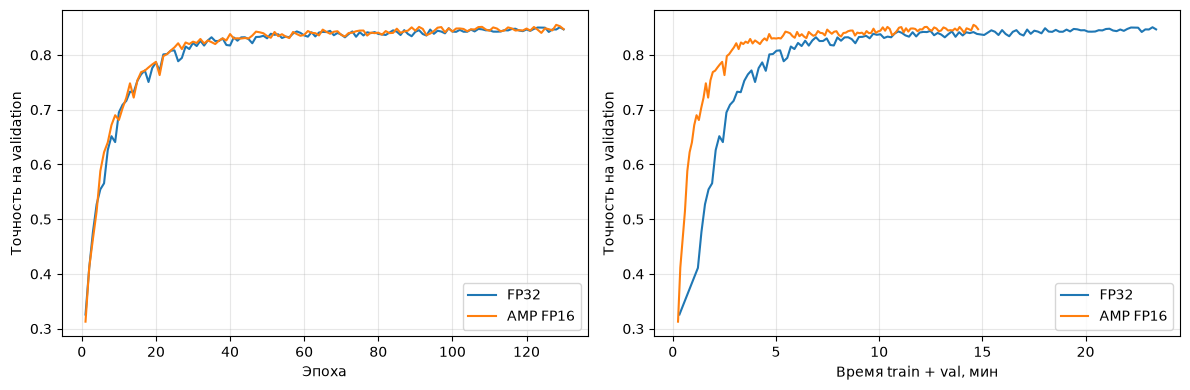

In [4]:
import matplotlib.pyplot as plt
import pandas as pd


def summarize(history):
    best = history.loc[history["val_acc"].idxmax()]
    return {
        "best_val_acc_pct": 100 * best["val_acc"],
        "best_epoch": int(best["epoch"]),
        "last_val_acc_pct": 100 * history["val_acc"].iloc[-1],
        "last_5_val_acc_pct": 100 * history["val_acc"].tail(5).mean(),
        "train_val_seconds": history["seconds"].sum(),
    }


summary = pd.DataFrame({
    "FP32": summarize(fp32_history),
    "AMP FP16": summarize(amp_history),
}).T
summary.to_csv(ARTIFACTS / "comparison.csv")
display(summary.round(2))

delta = summary.loc["AMP FP16", "last_5_val_acc_pct"] - summary.loc["FP32", "last_5_val_acc_pct"]
speedup = summary.loc["FP32", "train_val_seconds"] / summary.loc["AMP FP16", "train_val_seconds"]
print(f"AMP − FP32 за последние пять эпох {delta:+.2f} п.п.")
print(f"Ускорение train + val {speedup:.2f}×")

fig, (by_epoch, by_time) = plt.subplots(1, 2, figsize=(12, 4))
for label, history in (("FP32", fp32_history), ("AMP FP16", amp_history)):
    by_epoch.plot(history["epoch"], history["val_acc"], label=label)
    by_time.plot(history["seconds"].cumsum() / 60, history["val_acc"], label=label)

by_epoch.set(xlabel="Эпоха", ylabel="Точность на validation")
by_time.set(xlabel="Время train + val, мин", ylabel="Точность на validation")
for ax in (by_epoch, by_time):
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig(ARTIFACTS / "validation_accuracy.png", dpi=160)
plt.show()